# 🏠 House Price Prediction using Multiple Linear Regression

**Goal:** predict the sale price of a house (in ₹ lakhs) from its size, location, age and amenities, and test how good the model is.

**Why Linear Regression?** It is simple, fast and fully interpretable: every coefficient tells us how much the price changes when a feature changes. That makes the model easy to explain and defend.

**Workflow**
1. Load data → 2. Clean data → 3. Explore → 4. Feature engineering → 5. Train/test split → 6. Train → 7. Evaluate → 8. Check assumptions → 9. Predict

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import train_model as tm          # reuse the project's pipeline code
sns.set_theme(style="whitegrid", palette="deep")
%matplotlib inline

## 1. Load the data

In [2]:
df = pd.read_csv("../data/housing_data.csv")
print(df.shape)
df.head()

(2010, 13)


,area_sqft,bedrooms,bathrooms,age_years,floor,total_floors,parking_spaces,furnishing,locality_type,distance_to_center_km,has_lift,has_security,price_lakhs
0,1432,3,2,10.0,1,1,1,Unfurnished,Mid-range,7.7,0,1,83.42
1,930,2,3,13.0,14,18,1,NaN,Suburban,17.8,1,0,31.63
2,1600,4,4,8.0,5,11,2,Unfurnished,Suburban,23.8,1,0,48.14
3,913,2,1,8.0,12,14,2,Semi-furnished,Prime,4.4,1,1,98.19
4,1516,3,3,14.0,13,18,2,Unfurnished,Suburban,22.8,1,1,67.48


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2010 entries, 0 to 2009
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   area_sqft              2010 non-null   int64  
 1   bedrooms               2010 non-null   int64  
 2   bathrooms              2010 non-null   int64  
 3   age_years              1949 non-null   float64
 4   floor                  2010 non-null   int64  
 5   total_floors           2010 non-null   int64  
 6   parking_spaces         2010 non-null   int64  
 7   furnishing             1969 non-null   str    
 8   locality_type          2010 non-null   str    
 9   distance_to_center_km  1970 non-null   float64
 10  has_lift               2010 non-null   int64  
 11  has_security           2010 non-null   int64  
 12  price_lakhs            2010 non-null   float64
dtypes: float64(3), int64(8), str(2)
memory usage: 204.3 KB


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
area_sqft,2010.0,1247.79,432.76,350.0,956.25,1183.50,1526.00,2963.00
bedrooms,2010.0,2.63,1.01,1.0,2.00,3.00,3.00,5.00
bathrooms,2010.0,2.67,1.21,1.0,2.00,3.00,3.00,6.00
age_years,1949.0,9.99,6.83,0.0,5.00,8.00,13.00,40.00
floor,2010.0,5.36,4.81,0.0,1.00,4.00,8.00,20.00
total_floors,2010.0,10.53,5.85,1.0,5.00,11.00,16.00,20.00
parking_spaces,2010.0,1.06,0.66,0.0,1.00,1.00,1.00,2.00
distance_to_center_km,1970.0,12.39,6.56,0.5,7.40,11.20,18.70,26.90
has_lift,2010.0,0.73,0.45,0.0,0.00,1.00,1.00,1.00
has_security,2010.0,0.63,0.48,0.0,0.00,1.00,1.00,1.00


## 2. Clean the data
The raw data has duplicates, missing values and price outliers (deliberately, to practise cleaning).

In [5]:
print("Duplicate rows :", df.duplicated().sum())
print("\nMissing values:\n", df.isna().sum()[df.isna().sum() > 0])

Duplicate rows : 10

Missing values:
 age_years                61
furnishing               41
distance_to_center_km    40
dtype: int64


In [6]:
df = tm.clean_data(df)   # drops duplicates + price outliers; missing features are imputed inside the model pipeline
print("\nRows remaining:", len(df))

  Removed 10 duplicate rows
  Removed 0 rows with missing target
  Removed 5 price outliers (> 268.4 lakhs)
  Missing feature values (imputed later in the pipeline):
age_years                60
distance_to_center_km    40
furnishing               40

Rows remaining: 1995


**Cleaning decisions**
- **Duplicates** are removed (they would leak between train and test sets).
- **Outliers** in price are removed with the IQR rule (> Q3 + 3×IQR), which only removes extreme values.
- **Missing values** are filled *inside* the pipeline (median for numbers, most frequent for categories), learned from the training set only, to avoid data leakage.

## 3. Exploratory Data Analysis

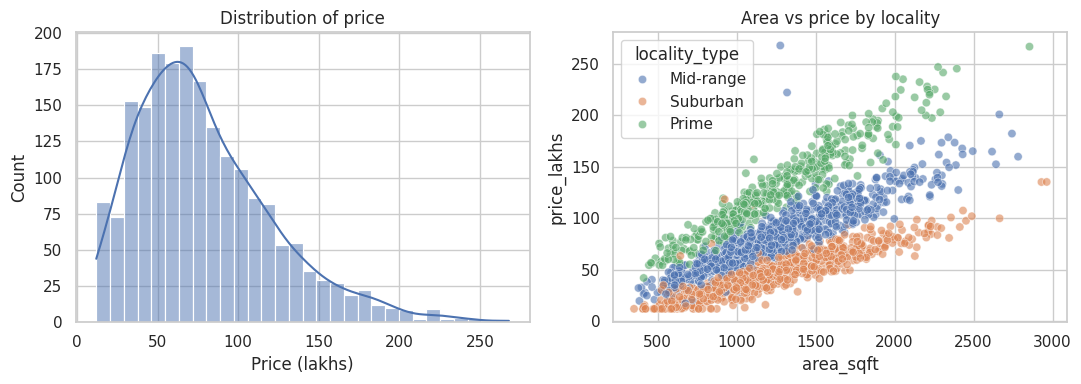

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df.price_lakhs, kde=True, ax=ax[0]); ax[0].set(title="Distribution of price", xlabel="Price (lakhs)")
sns.scatterplot(data=df, x="area_sqft", y="price_lakhs", hue="locality_type", alpha=.6, ax=ax[1])
ax[1].set(title="Area vs price by locality")
plt.tight_layout(); plt.show()

**Observation:** price rises with area, but the *slope differs by locality*: a square foot in a Prime area is worth more than one in a Suburb. We will use this in feature engineering.

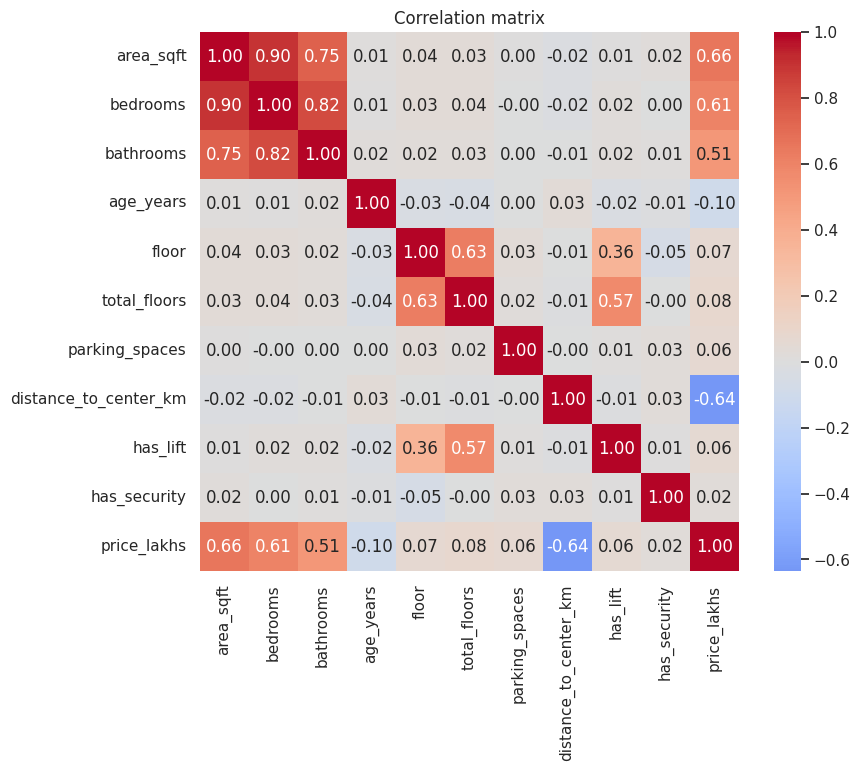

In [8]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[tm.NUMERIC_FEATURES + [tm.TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix"); plt.show()

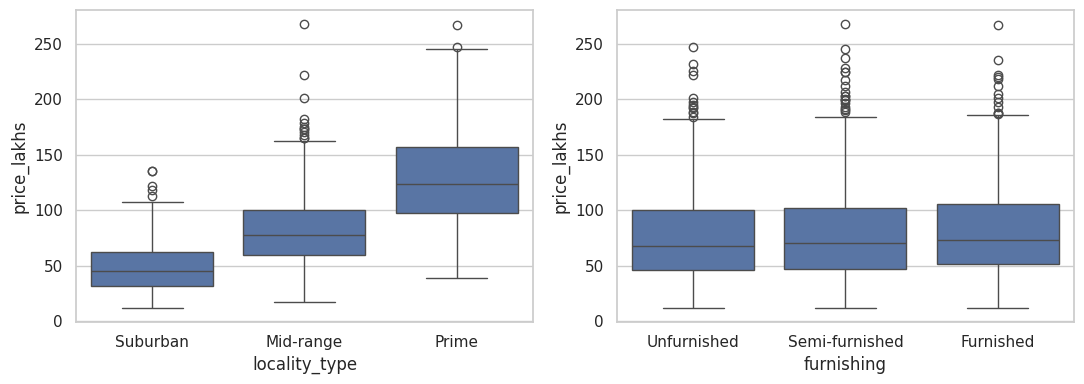

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=df, x="locality_type", y="price_lakhs", order=["Suburban","Mid-range","Prime"], ax=ax[0])
sns.boxplot(data=df, x="furnishing", y="price_lakhs", order=["Unfurnished","Semi-furnished","Furnished"], ax=ax[1])
plt.tight_layout(); plt.show()

## 4. Feature engineering
We add an **interaction term** between area and locality so the model can learn a different price-per-sq-ft for each locality type.

In [10]:
df = tm.add_features(df)
df[["area_sqft", "locality_type", "area_x_prime", "area_x_midrange"]].head()

,area_sqft,locality_type,area_x_prime,area_x_midrange
0,1432,Mid-range,0,1432
1,930,Suburban,0,0
2,1600,Suburban,0,0
3,913,Prime,913,0
4,1516,Suburban,0,0


## 5. Train / test split
We keep 20% of the data hidden from the model to test it honestly on unseen houses.

In [11]:
all_cols = tm.NUMERIC_FEATURES + tm.ENGINEERED_FEATURES + tm.CATEGORICAL_FEATURES
X, y = df[all_cols], df[tm.TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train: {len(X_train)} | Test: {len(X_test)}")

Train: 1596 | Test: 399


## 6. Build and train the model
The pipeline imputes missing values, scales numeric features, one-hot encodes categories, then fits `LinearRegression`.

In [12]:
model = tm.build_pipeline().fit(X_train, y_train)
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers cont

## 7. Evaluate the model
| Metric | Meaning |
|---|---|
| **R²** | share of price variation the model explains (1 = perfect) |
| **MAE** | average error in lakhs |
| **RMSE** | like MAE but penalises big errors more |
| **MAPE** | average error as a % of the true price |

In [13]:
n_feat = model.named_steps["preprocess"].transform(X_train[:1]).shape[1]
pred_train, pred_test = model.predict(X_train), model.predict(X_test)
results = pd.DataFrame({"Train": tm.regression_metrics(y_train, pred_train, n_feat),
                        "Test":  tm.regression_metrics(y_test,  pred_test,  n_feat)})
results

,Train,Test
R2,0.9409,0.9651
Adjusted_R2,0.9403,0.9637
MAE,6.7000,6.3430
RMSE,10.3380,8.2710
MAPE_percent,10.3600,9.8000


In [14]:
cv = KFold(5, shuffle=True, random_state=42)
cv_r2 = cross_val_score(tm.build_pipeline(), X, y, cv=cv, scoring="r2")
baseline = np.sqrt(mean_squared_error(y_test, np.full(len(y_test), y_train.mean())))
print(f"5-fold CV R²: {cv_r2.mean():.3f} ± {cv_r2.std():.3f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, pred_test)):.2f} lakhs   vs   naive 'predict the average' RMSE: {baseline:.2f} lakhs")

5-fold CV R²: 0.945 ± 0.018
Test RMSE: 8.27 lakhs   vs   naive 'predict the average' RMSE: 44.45 lakhs


**Reading the results**
- Test R² is close to the train R² and to the cross-validation R² → the model **generalises well** and is not overfitting.
- RMSE is far below the "always predict the mean" baseline → the model has real predictive value.

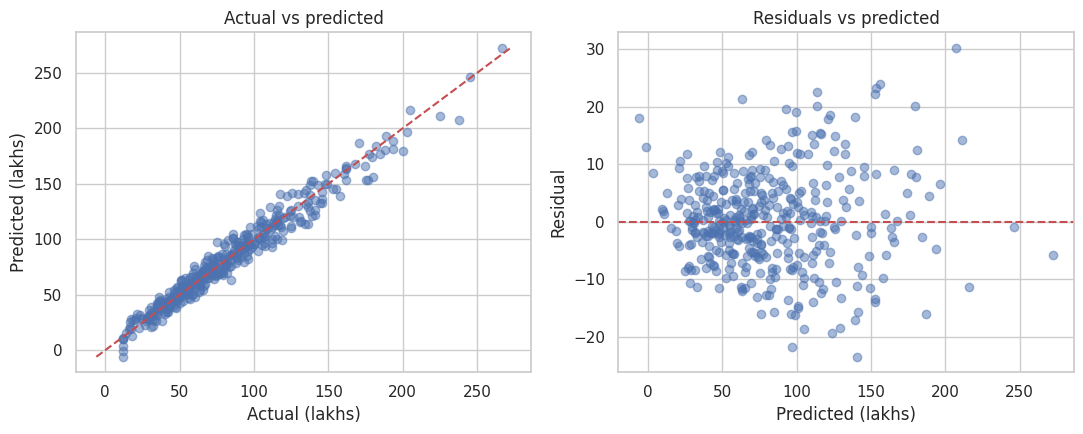

In [15]:
residuals = y_test - pred_test
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(y_test, pred_test, alpha=.5)
lims = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
ax[0].plot(lims, lims, "r--"); ax[0].set(title="Actual vs predicted", xlabel="Actual (lakhs)", ylabel="Predicted (lakhs)")
ax[1].scatter(pred_test, residuals, alpha=.5); ax[1].axhline(0, color="r", ls="--")
ax[1].set(title="Residuals vs predicted", xlabel="Predicted (lakhs)", ylabel="Residual")
plt.tight_layout(); plt.show()

## Baseline vs improved model
Does the interaction feature actually help? Compare the model with and without it:

In [16]:
rows = {}
for label, feats in [("Without interaction", tm.NUMERIC_FEATURES), ("With interaction (final)", tm.NUMERIC_FEATURES + tm.ENGINEERED_FEATURES)]:
    cols = feats + tm.CATEGORICAL_FEATURES
    m = tm.build_pipeline(feats).fit(X_train[cols], y_train)
    p = m.predict(X_test[cols])
    rows[label] = {"Test R²": r2_score(y_test, p), "Test RMSE": np.sqrt(mean_squared_error(y_test, p)),
                   "CV R²": cross_val_score(tm.build_pipeline(feats), X[cols], y, cv=cv, scoring="r2").mean()}
pd.DataFrame(rows).T.round(3)

,Test R²,Test RMSE,CV R²
Without interaction,0.924,12.194,0.909
With interaction (final),0.965,8.271,0.945


## What drives the price? (model coefficients)

In [17]:
coef = tm.coefficient_table(model)   # also saves the chart
coef.round(2)

,feature,standardized_coefficient
0,area_x_prime,27.31
1,area_sqft,15.78
2,area_x_midrange,15.24
3,furnishing_Unfurnished,-7.30
4,distance_to_center_km,-5.38
5,locality_type_Prime,4.48
6,furnishing_Semi-furnished,-3.94
7,age_years,-3.91
8,bathrooms,3.25
9,parking_spaces,2.67


Coefficients are **standardized**, so they are comparable: each shows the change in price (₹ lakhs) for a one-standard-deviation increase in that feature.
Area (and especially area in a Prime locality), furnishing, and distance from the city centre are the strongest drivers.

## 8. Check the linear-regression assumptions
| Assumption | Check |
|---|---|
| Linearity | Residuals vs predicted shows no strong curve |
| Independent errors | Durbin-Watson ≈ 2 |
| Constant variance | Breusch-Pagan test |
| Normal residuals | Histogram / Q-Q plot |
| No multicollinearity | VIF |

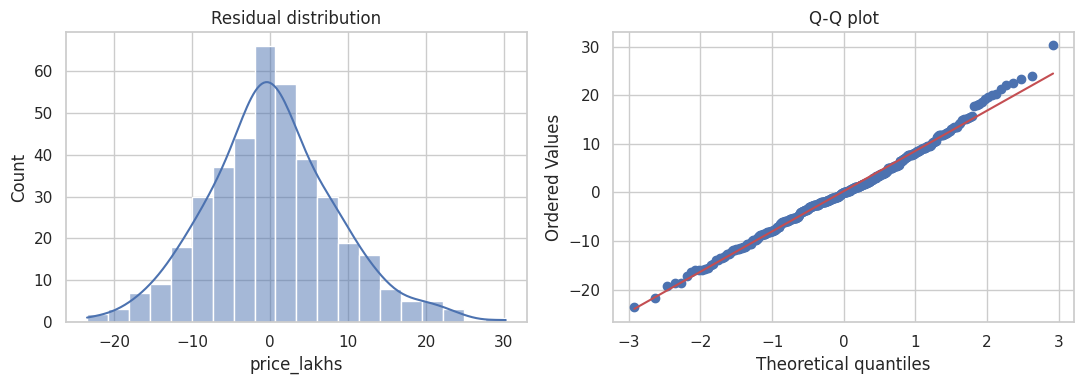

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(residuals, kde=True, ax=ax[0]); ax[0].set_title("Residual distribution")
stats.probplot(residuals, dist="norm", plot=ax[1]); ax[1].set_title("Q-Q plot")
plt.tight_layout(); plt.show()

In [19]:
diag = tm.assumption_checks(model, X_train, y_train)
pd.Series(diag)

ols_r2_train                                                           0.9409
f_test_p_value                                                            0.0
durbin_watson                                                           2.034
breusch_pagan_p_value                                                   0.006
shapiro_wilk_p_value                                                      0.0
max_vif                                                                 14.02
non_significant_features    [bedrooms, locality_type_Prime, locality_type_...
dtype: object

**Honest interpretation**
- **Independence:** Durbin-Watson is about 2, so there is no autocorrelation. ✅
- **Linearity:** the residual plot shows no strong curve. ✅
- **Constant variance:** Breusch-Pagan still flags mild heteroscedasticity (errors grow slightly for expensive houses). ⚠️
- **Normality:** residuals are slightly heavy-tailed. With ~1,600 training rows this has little effect on predictions. ⚠️
- **Multicollinearity:** the high VIF values belong to `area_sqft` and the interaction terms, which are *structurally* correlated by design; predictions remain reliable. ⚠️

*Possible improvements:* try Ridge/Lasso regularisation, weighted least squares, or a non-linear model such as Random Forest and compare.

## 9. Make a prediction

In [20]:
new_house = pd.DataFrame([{
    "area_sqft": 1500, "bedrooms": 3, "bathrooms": 2, "age_years": 4, "floor": 5, "total_floors": 12,
    "parking_spaces": 1, "distance_to_center_km": 5.0, "has_lift": 1, "has_security": 1,
    "furnishing": "Semi-furnished", "locality_type": "Prime"}])
price = model.predict(tm.add_features(new_house))[0]
print(f"Predicted price: ₹ {price:,.1f} lakhs  (≈ ₹ {price/100:.2f} crore)")

Predicted price: ₹ 152.1 lakhs  (≈ ₹ 1.52 crore)


## Conclusion
A multiple linear regression model with an area × locality interaction explains about **96% of the variation** in house prices on unseen data, with an average error of roughly **₹6 lakhs (about 10%)**. Location and size are the dominant price drivers. The model is simple, interpretable, and validated with a hold-out set, 5-fold cross-validation and assumption diagnostics.